# Parte 2: del LLM al clasificador

**Objetivo:** comparar tres formas de clasificar titulares en politica, economia,
deportes y ciencia_tecnologia:
1. Zero-shot sin entrenar (el piso que hay que superar).
2. Un LLM (Gemini) que etiqueta todo el dataset: supervisión débil.
3. DistilBERT multilingüe afinado con las etiquetas del LLM.

**Referencia para evaluar:** la columna `etiqueta` (sección del diario, Parte 1).
El modelo se entrena con `etiqueta_llm` y se evalúa contra `etiqueta` en un test que no se usa hasta el final.


In [1]:
import json
import time
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from transformers import pipeline

c:\GitHub\Python_intermedio_2026\tarea_1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
SEMILLA = 42
CARPETA_DATOS = Path("datos")
CARPETA_MODELO = Path("modelo")
CARPETA_MODELO.mkdir(exist_ok=True)

noticias = pd.read_csv(CARPETA_DATOS / "noticias.csv")
noticias["bajada"] = noticias["bajada"].fillna("")
print(noticias.shape)
noticias["etiqueta"].value_counts()

(384, 7)


etiqueta
economia              99
deportes              98
ciencia_tecnologia    95
politica              92
Name: count, dtype: int64

## Paso 1 · Línea base zero-shot
Clasifico 40 titulares (10 por categoría) con `Recognai/bert-base-spanish-wwm-cased-xnli`, un BERT en español entrenado para inferencia (XNLI). No ve ningún ejemplo de nuestras categorías: su F1 es el piso que el modelo afinado debe superar.

In [3]:
muestra_zero_shot = noticias.groupby("etiqueta").sample(10, random_state=SEMILLA)
muestra_zero_shot["etiqueta"].value_counts()

etiqueta
ciencia_tecnologia    10
deportes              10
economia              10
politica              10
Name: count, dtype: int64

In [4]:
MODELO_ZERO_SHOT = "Recognai/bert-base-spanish-wwm-cased-xnli"
clasificador_zero_shot = pipeline("zero-shot-classification", model=MODELO_ZERO_SHOT)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 853.10it/s]


In [5]:
# El modelo entiende mejor palabras naturales
NOMBRES_NATURALES = {
    "política": "politica",
    "economía": "economia",
    "deportes": "deportes",
    "ciencia y tecnología": "ciencia_tecnologia",
}

inicio = time.time()
resultados = clasificador_zero_shot(
    muestra_zero_shot["titular"].tolist(),
    candidate_labels=list(NOMBRES_NATURALES.keys()),
    hypothesis_template="Esta noticia trata sobre {}.",
)
segundos_zero_shot = (time.time() - inicio) / len(muestra_zero_shot)

predicciones = []
for resultado in resultados:
    mejor_opcion = resultado["labels"][0]
    predicciones.append(NOMBRES_NATURALES[mejor_opcion])
muestra_zero_shot["prediccion_zero_shot"] = predicciones

In [6]:
reales = muestra_zero_shot["etiqueta"]
predichas = muestra_zero_shot["prediccion_zero_shot"]
accuracy_zero_shot = accuracy_score(reales, predichas)
f1_zero_shot = f1_score(reales, predichas, average="macro")

print(f"Zero-shot · accuracy: {accuracy_zero_shot:.2f} · F1 macro: {f1_zero_shot:.2f}")
print(f"Tiempo por titular: {segundos_zero_shot:.2f} s")

Zero-shot · accuracy: 0.62 · F1 macro: 0.60
Tiempo por titular: 0.42 s


**Resultado:** sin ningún entrenamiento, el zero-shot acierta el 62 % de los 40 titulares (F1 macro = 0.60) y tarda unos 0.4 s por titular. Este es el piso que el modelo afinado debe superar.

## Paso 2 · Supervisión débil con un LLM
Gemini etiqueta todas las noticias con un prompt que define cada categoría. Envío lotes de 20 para no pasar el límite de la capa gratuita, y el avance se guarda en `datos/etiquetas_llm.csv` (titular, etiqueta_llm, confianza, modelo_llm, fecha).
Si el archivo ya existe, no se vuelve a llamar a la API. La clave se lee de `.env`, que no se sube a GitHub.

In [7]:
from dotenv import load_dotenv
from google import genai
from google.genai import types

load_dotenv()  # lee GEMINI_API_KEY del archivo .env
cliente = genai.Client()

In [8]:
for modelo_disponible in cliente.models.list():
    if "flash" in modelo_disponible.name:
        print(modelo_disponible.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


In [9]:
MODELO_LLM = "gemini-3.5-flash"

INSTRUCCIONES = """Eres editor de un diario peruano. Clasifica cada noticia en UNA categoría:
- politica: Congreso, Gobierno, elecciones, partidos, justicia, relaciones exteriores.
- economia: mercados, empresas, empleo, precios, impuestos, minería, presupuesto.
- deportes: fútbol, vóley, atletismo y cualquier competencia deportiva.
- ciencia_tecnologia: ciencia, espacio, ambiente, tecnología, IA, internet, videojuegos.
Responde SOLO con una lista JSON, un objeto por noticia y en el mismo orden:
[{"id": 0, "etiqueta": "politica", "confianza": 0.95}]
"confianza" va de 0 a 1 e indica qué tan seguro estás."""


def etiquetar_lote(lote):
    """Envía varias noticias en una sola llamada. Devuelve [] si falla dos veces."""
    lineas = []
    for posicion, fila in enumerate(lote.itertuples()):
        lineas.append(f"{posicion}. Titular: {fila.titular} | Bajada: {fila.bajada}")
    texto = INSTRUCCIONES + "\n\nNoticias:\n" + "\n".join(lineas)

    for intento in [1, 2]:
        try:
            respuesta = cliente.models.generate_content(
                model=MODELO_LLM,
                contents=texto,
                config=types.GenerateContentConfig(
                    temperature=0, response_mime_type="application/json"
                ),
            )
            return json.loads(respuesta.text)
        except Exception as error:
            print("Falló el intento", intento, ":", error)
            time.sleep(30)
    return []

In [10]:
inicio = time.time()
prueba_llm = etiquetar_lote(noticias.head(3))
segundos_llm = (time.time() - inicio) / 3
print(prueba_llm)
print(f"Tiempo por titular: {segundos_llm:.2f} s")

[{'id': 0, 'etiqueta': 'deportes', 'confianza': 0.99}, {'id': 1, 'etiqueta': 'deportes', 'confianza': 0.98}, {'id': 2, 'etiqueta': 'deportes', 'confianza': 0.97}]
Tiempo por titular: 1.22 s


In [11]:
archivo_llm = CARPETA_DATOS / "etiquetas_llm.csv"
if archivo_llm.exists():
    etiquetas_llm = pd.read_csv(archivo_llm)
else:
    columnas_llm = ["titular", "etiqueta_llm", "confianza", "modelo_llm", "fecha"]
    etiquetas_llm = pd.DataFrame(columns=columnas_llm)

pendientes = noticias[~noticias["titular"].isin(etiquetas_llm["titular"])]
print("Noticias por etiquetar:", len(pendientes))

Noticias por etiquetar: 0


In [12]:
TAMANO_LOTE = 20
for inicio_lote in range(0, len(pendientes), TAMANO_LOTE):
    lote = pendientes.iloc[inicio_lote:inicio_lote + TAMANO_LOTE]
    nuevas = []
    for respuesta in etiquetar_lote(lote):
        nuevas.append({
            "titular": lote.iloc[int(respuesta["id"])]["titular"],
            "etiqueta_llm": respuesta["etiqueta"],
            "confianza": respuesta["confianza"],
            "modelo_llm": MODELO_LLM,
            "fecha": date.today().isoformat(),
        })
    etiquetas_llm = pd.concat([etiquetas_llm, pd.DataFrame(nuevas)], ignore_index=True)
    etiquetas_llm.to_csv(archivo_llm, index=False, encoding="utf-8")
    print("Etiquetadas:", len(etiquetas_llm), "de", len(noticias))
    time.sleep(6)  # respeta el límite de solicitudes por minuto de la capa gratuita

**Nota sobre el límite gratuito de Gemini:** la capa gratuita permite 20 solicitudes por día
para cada modelo. Las primeras 300 noticias se etiquetaron con `gemini-3.8-flash` (15 lotes) y, al agotarse su cuota, las 84 restantes con `gemini-3.5-flash`. La columna `modelo_llm` de `etiquetas_llm.csv` registra qué modelo etiquetó cada noticia. Durante el proceso también hubo errores temporales 503 (alta demanda), que se resolvieron con el reintento automático.

In [13]:
fuera_de_lista = etiquetas_llm[~etiquetas_llm["etiqueta_llm"].isin(CATEGORIAS)]
print("Etiquetas fuera de las 4 categorías:", len(fuera_de_lista))
print("Noticias por modelo:", etiquetas_llm["modelo_llm"].value_counts().to_dict())

# Si ejecutas esta celda dos veces, primero se quitan las columnas de la vez anterior
noticias = noticias.drop(columns=["etiqueta_llm", "confianza"], errors="ignore")
columnas_unir = ["titular", "etiqueta_llm", "confianza"]
noticias = noticias.merge(etiquetas_llm[columnas_unir], on="titular", how="left")
coincide_con_seccion = (noticias["etiqueta_llm"] == noticias["etiqueta"]).mean()
print(f"El LLM coincide con la sección del diario en el {coincide_con_seccion:.0%} de noticias")
noticias["etiqueta_llm"].value_counts()

Etiquetas fuera de las 4 categorías: 0
Noticias por modelo: {'gemini-3.8-flash': 300, 'gemini-3.5-flash': 84}
El LLM coincide con la sección del diario en el 92% de noticias


etiqueta_llm
politica              103
deportes               98
economia               95
ciencia_tecnologia     88
Name: count, dtype: int64

**Resultado:** Gemini etiquetó las 384 noticias, todas en una de las 4 categorías. Sus etiquetas coinciden con la sección del diario en el 92% de los casos.

### Auditoría humana de 20 casos
Leo 20 noticias elegidas al azar (`random_state=42`) y escribo mi categoría sin mirar la del LLM. Luego cuento en cuántas coincidimos y comento los desacuerdos.

In [14]:
pd.set_option("display.max_colwidth", 150)
auditoria = noticias.sample(20, random_state=SEMILLA)[["titular", "etiqueta_llm"]]
auditoria = auditoria.reset_index(drop=True)
auditoria

,titular,etiqueta_llm
0,Carlos Mesía: “En dos semanas debe estar debatiéndose [el dictamen de facultades] en el pleno del Senado”,politica
1,¿Lima puede elegir a su alcalde en segunda vuelta? Esto tendría que cambiar para aplicar en el futuro propuesta de Francis Allison,politica
2,NASA: los cuatro astronautas de Crew 12 retornaron a la tierra,ciencia_tecnologia
3,Científicos descubren cómo predecir cuándo una inteligencia artificial dará respuestas peligrosas,ciencia_tecnologia
4,"“El día de mañana me encantaría ver a tantas niñas entrando al automovilismo”: Annia Cillóniz, líder en la categoría S1600, sobre sus sueños en Ca...",deportes
5,Noruega estudia prohibir temporalmente las gafas inteligentes,ciencia_tecnologia
6,"Neymar se rinde ante Lamine Yamal: ""Es el mejor del mundo""",deportes
7,"El dólar abre a la baja en S/3,42 ante debilitamiento de la divisa estadounidense",economia
8,"Las empresas de IA son incapaces de controlar sus modelos, alerta un exinvestigador de OpenAI",ciencia_tecnologia
9,Keiko Fujimori ratifica su respaldo al ministro César Astudillo y al jefe de la PNP Fredy López,politica


In [15]:
etiquetas_humanas = [
    "politica",  # 0
    "politica",  # 1
    "ciencia_tecnologia",  # 2
    "ciencia_tecnologia",  # 3
    "deportes",  # 4
    "ciencia_tecnologia",  # 5
    "deportes",  # 6
    "economia",  # 7
    "ciencia_tecnologia",  # 8
    "politica",  # 9
    "politica",  # 10
    "economia",  # 11
    "economia",  # 12
    "politica",  # 13
    "economia",  # 14
    "economia",  # 15
    "economia",  # 16
    "ciencia_tecnologia",  # 17
    "ciencia_tecnologia",  # 18
    "politica",  # 19
]


In [16]:
auditoria["etiqueta_humana"] = etiquetas_humanas
auditoria["coinciden"] = auditoria["etiqueta_llm"] == auditoria["etiqueta_humana"]
aciertos = int(auditoria["coinciden"].sum())
print(f"Acuerdo LLM–humano: {aciertos}/20 = {aciertos / 20:.0%}")
auditoria[~auditoria["coinciden"]]

Acuerdo LLM–humano: 20/20 = 100%


,titular,etiqueta_llm,etiqueta_humana,coinciden


**Resultado de la auditoría:** coincidí con el LLM en 20 de 20 casos (100 %). Aun así, el LLM no coincide con la sección del diario en 30 de las 384 noticias (8 %). En deportes no hay ningún desacuerdo; la mayoría son temas que cruzan categorías, como la Ley MAPE de minería (sección política, el LLM dice economía) o los sistemas de alerta de El Niño (sección tecnología, el LLM dice política). La sección del diario no siempre describe el tema del titular.

## Paso 3 · Partición 70 / 15 / 15
Split estratificado por categoría con `random_state=42`. Train y validación usan la etiqueta del LLM (no hay etiquetas manuales); test se compara con la sección del diario y no se toca hasta el paso 5.


In [17]:
# Solo entran las noticias con una etiqueta del LLM válida
datos_modelo = noticias[noticias["etiqueta_llm"].isin(CATEGORIAS)].copy()

entrenamiento, resto = train_test_split(
    datos_modelo, test_size=0.30, stratify=datos_modelo["etiqueta"], random_state=SEMILLA
)
validacion, prueba = train_test_split(
    resto, test_size=0.50, stratify=resto["etiqueta"], random_state=SEMILLA
)
print("Train:", len(entrenamiento), "· Val:", len(validacion), "· Test:", len(prueba))

pd.DataFrame({
    "train": entrenamiento["etiqueta"].value_counts(),
    "val": validacion["etiqueta"].value_counts(),
    "test": prueba["etiqueta"].value_counts(),
})

Train: 268 · Val: 58 · Test: 58


,train,val,test
etiqueta,,,
ciencia_tecnologia,66,14,15
deportes,69,15,14
economia,69,15,15
politica,64,14,14


**Resultado:** 268 noticias para entrenar (70 %), 58 para validar (15 %) y 58 para el test (15 %), con las 4 categorías en proporciones parecidas en los tres conjuntos.

## Paso 4 · Fine-tuning de DistilBERT multilingüe
`distilbert-base-multilingual-cased`, solo con el titular (la app recibirá titulares), 3 épocas, batch 16, evaluación por época y mejor modelo según el F1 macro de validación.

In [18]:
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer, set_seed

MODELO_BASE = "distilbert-base-multilingual-cased"
id_a_etiqueta = dict(enumerate(CATEGORIAS))
etiqueta_a_id = {categoria: numero for numero, categoria in id_a_etiqueta.items()}

tokenizador = AutoTokenizer.from_pretrained(MODELO_BASE)


def tokenizar(lote):
    return tokenizador(lote["text"], truncation=True, max_length=64, padding="max_length")


def preparar(tabla, columna_etiqueta):
    """Convierte una tabla en un Dataset de titulares tokenizados."""
    datos = Dataset.from_dict({
        "text": tabla["titular"].tolist(),
        "label": tabla[columna_etiqueta].map(etiqueta_a_id).tolist(),
    })
    return datos.map(tokenizar, batched=True)


# Train y val usan la etiqueta del LLM; test, la sección del diario
datos_train = preparar(entrenamiento, "etiqueta_llm")
datos_val = preparar(validacion, "etiqueta_llm")
datos_test = preparar(prueba, "etiqueta")

Map: 100%|██████████| 58/58 [00:00<00:00, 5978.32 examples/s]


In [20]:
# Fija el azar ANTES de crear el modelo: la capa nueva empieza igual en cada ejecución
set_seed(SEMILLA)

modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE, num_labels=4, id2label=id_a_etiqueta, label2id=etiqueta_a_id
)


def calcular_metricas(evaluacion):
    predicciones = np.argmax(evaluacion.predictions, axis=-1)
    return {
        "accuracy": accuracy_score(evaluacion.label_ids, predicciones),
        "f1_macro": f1_score(evaluacion.label_ids, predicciones, average="macro"),
    }


argumentos = TrainingArguments(
    output_dir=str(CARPETA_MODELO),
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1,
    seed=SEMILLA,
    report_to="none",
)
entrenador = Trainer(
    model=modelo,
    args=argumentos,
    train_dataset=datos_train,
    eval_dataset=datos_val,
    processing_class=tokenizador,
    compute_metrics=calcular_metricas,
)
entrenador.train()

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 483.70it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
c:\GitHub\Python_intermedio_2026\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is s

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.226040,0.917787,0.689655,0.631617
2,0.667349,0.610669,0.793103,0.772749
3,0.407662,0.530812,0.793103,0.774095


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.92s/it]
c:\GitHub\Python_intermedio_2026\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.22s/it]
c:\GitHub\Python_intermedio_2026\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.00s/it]


TrainOutput(global_step=51, training_loss=0.7670169905120251, metrics={'train_runtime': 156.0194, 'train_samples_per_second': 5.153, 'train_steps_per_second': 0.327, 'total_flos': 13313448400896.0, 'train_loss': 0.7670169905120251, 'epoch': 3.0})

In [21]:
entrenador.save_model(str(CARPETA_MODELO))

historial = pd.DataFrame(entrenador.state.log_history)
historial[historial["eval_f1_macro"].notna()][["epoch", "eval_loss", "eval_f1_macro"]]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.26s/it]


,epoch,eval_loss,eval_f1_macro
1,1.0,0.917787,0.631617
3,2.0,0.610669,0.772749
5,3.0,0.530812,0.774095


**Resultado:** el F1 macro en validación subió de 0.63 (época 1) a 0.77 (época 2) y se mantuvo en 0.77 en la época 3, que fue la mejor por muy poco. Ese modelo quedó guardado en `modelo/`.
La semilla se fija con `set_seed(42)` antes de crear el modelo: sin eso, la capa clasificadora nueva empieza al azar y cada ejecución da un resultado distinto.

## Paso 5 · Evaluación final en test
Primera y única vez que se usa el test reservado (58 noticias), comparado con la sección del diario.


In [22]:
inicio = time.time()
salida_test = entrenador.predict(datos_test)
segundos_modelo = (time.time() - inicio) / len(prueba)

numeros_predichos = np.argmax(salida_test.predictions, axis=-1)
prueba["prediccion_modelo"] = [id_a_etiqueta[numero] for numero in numeros_predichos]

accuracy_test = accuracy_score(prueba["etiqueta"], prueba["prediccion_modelo"])
f1_test = f1_score(prueba["etiqueta"], prueba["prediccion_modelo"], average="macro")
print(f"DistilBERT en test · accuracy: {accuracy_test:.2f} · F1 macro: {f1_test:.2f}")
print(classification_report(
    prueba["etiqueta"], prueba["prediccion_modelo"], digits=2, zero_division=0
))

c:\GitHub\Python_intermedio_2026\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


DistilBERT en test · accuracy: 0.81 · F1 macro: 0.80
                    precision    recall  f1-score   support

ciencia_tecnologia       1.00      0.47      0.64        15
          deportes       0.86      0.86      0.86        14
          economia       0.71      1.00      0.83        15
          politica       0.81      0.93      0.87        14

          accuracy                           0.81        58
         macro avg       0.85      0.81      0.80        58
      weighted avg       0.85      0.81      0.80        58



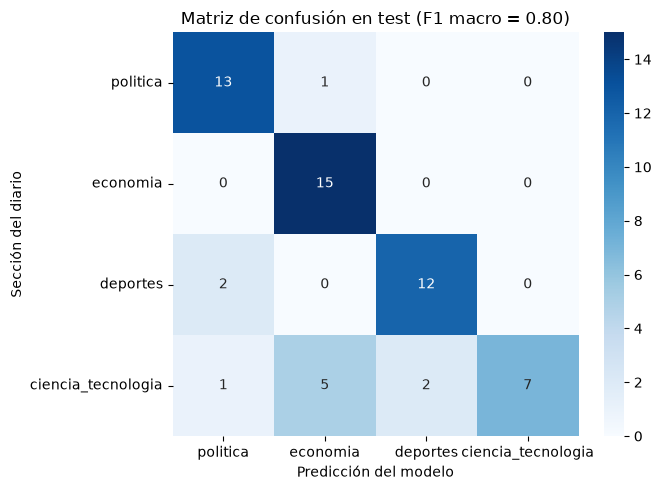

In [23]:
matriz = confusion_matrix(prueba["etiqueta"], prueba["prediccion_modelo"], labels=CATEGORIAS)

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues",
    xticklabels=CATEGORIAS, yticklabels=CATEGORIAS,
)
plt.xlabel("Predicción del modelo")
plt.ylabel("Sección del diario")
plt.title(f"Matriz de confusión en test (F1 macro = {f1_test:.2f})")
plt.tight_layout()
plt.show()

### Reflexión por categoría
DistilBERT acertó 47 de los 58 titulares del test (accuracy 0.81, F1 macro 0.80).

- **Mejor: política (F1 = 0.87).** Acertó 13 de 14. Es la categoría con el vocabulario más
  marcado: Congreso, ministros, bancadas y nombres de políticos.
- **Peor: ciencia y tecnología (F1 = 0.64).** Solo acertó 7 de 15. Es la categoría más variada
  (inteligencia artificial, videojuegos, clima, medio ambiente, seguridad digital) y no tiene
  palabras propias que la distingan.
- **Confusión más frecuente: ciencia y tecnología → economía (5 casos).** Son noticias de
  ambiente o seguridad digital con empresas, cifras o dinero de por medio: los centros de datos
  de Google en Finlandia, El Niño, las estafas digitales a adultos mayores, la minería ilegal en
  Madre de Dios y el Informe Planeta Vivo («la fauna silvestre cae 73 %»). Economía acertó sus
  15 titulares, pero porque funciona como cajón de sastre: también se llevó 6 que no eran suyos.
- **El modelo se guía por palabras sueltas:** la reseña del videojuego «Ace Combat 8» y el
  Nobel de Física que dice «Estoy muy orgulloso» fueron a deportes; una frase de Mourinho
  sobre Vinícius y la etapa del rally Caminos del Inca entre Cusco y Puno fueron a política,
  posiblemente por las declaraciones entre comillas y los nombres de regiones, frecuentes en
  las noticias políticas.

In [24]:
accuracy_llm = accuracy_score(prueba["etiqueta"], prueba["etiqueta_llm"])
f1_llm = f1_score(prueba["etiqueta"], prueba["etiqueta_llm"], average="macro")
print(f"LLM en test · accuracy: {accuracy_llm:.2f} · F1 macro: {f1_llm:.2f}")

LLM en test · accuracy: 0.95 · F1 macro: 0.95


**Resultado:** en el mismo test, Gemini acierta 55 de 58 titulares (F1 macro 0.95). Falla en 3 que mezclan temas: Trump y la «superinteligencia» (sección tecnología, Gemini dice política), la minería ilegal en Madre de Dios (tecnología → economía) y una declaración de la viceministra de Minas (política → economía). 
**DistilBERT falla en esos mismos 3:** como aprendió de las etiquetas de Gemini, hereda sus errores. Sus otros 8 errores son propios.


In [25]:
comparacion = pd.DataFrame([
    {
        "modelo": "Zero-shot (BERT español XNLI)",
        "evaluado_en": "40 titulares",
        "accuracy": accuracy_zero_shot,
        "f1_macro": f1_zero_shot,
        "segundos_por_titular": segundos_zero_shot,
        "costo": "gratis, local",
    },
    {
        "modelo": "LLM (Gemini 3.8 / 3.5 Flash)",
        "evaluado_en": f"test ({len(prueba)})",
        "accuracy": accuracy_llm,
        "f1_macro": f1_llm,
        "segundos_por_titular": segundos_llm,
        "costo": "API, 20 solicitudes gratis por día y modelo",
    },
    {
        "modelo": "DistilBERT afinado",
        "evaluado_en": f"test ({len(prueba)})",
        "accuracy": accuracy_test,
        "f1_macro": f1_test,
        "segundos_por_titular": segundos_modelo,
        "costo": "gratis, local (CPU)",
    },
])
comparacion.round(3)


,modelo,evaluado_en,accuracy,f1_macro,segundos_por_titular,costo
0,Zero-shot (BERT español XNLI),40 titulares,0.625,0.595,0.423,"gratis, local"
1,LLM (Gemini 3.8 / 3.5 Flash),test (58),0.948,0.949,1.224,"API, 20 solicitudes gratis por día y modelo"
2,DistilBERT afinado,test (58),0.810,0.798,0.043,"gratis, local (CPU)"


## Paso 6 · ¿Cuál usaría en un entorno real?

**Para el volumen de este proyecto, usaría el LLM.** En el test es claramente el más preciso (F1 0.95, frente a 0.80 de DistilBERT y 0.60 del zero-shot), y el volumen es bajo: El Comercio publicó unas 55 noticias al día en estas 4 secciones, que caben en 3 solicitudes de 20 titulares,
dentro de la capa gratuita.

**DistilBERT conviene si el volumen crece o se necesita una respuesta inmediata:** clasifica un titular en unos 0.04 s (Gemini tardó entre 1.2 y 3.5 s en mis ejecuciones), corre gratis en una laptop sin internet y no depende de una cuota. Antes habría que mejorar ciencia y tecnología
(F1 0.64), por ejemplo con más titulares de esa categoría. Una opción intermedia: que DistilBERT clasifique todo y envíe al LLM solo los titulares en los que tenga poca seguridad.

El zero-shot queda descartado: con F1 0.60 se equivoca en casi 4 de cada 10 titulares.

**Riesgos.** El LLM depende de un servicio externo que cambia: `gemini-2.5-flash` no estaba disponible para mi cuenta (error 404) y la cuota diaria se agotó a mitad del etiquetado, lo que obligó a cambiar de modelo. DistilBERT aprendió de las etiquetas del LLM y de noticias de solo
dos semanas de octubre de 2026: hereda los errores del LLM y habría que volver a entrenarlo cuando cambie la agenda informativa, por ejemplo después de las elecciones.

In [26]:
metricas = {
    "total_noticias": int(len(noticias)),
    "f1_test": round(float(f1_test), 4),
    "accuracy_test": round(float(accuracy_test), 4),
    "f1_zero_shot": round(float(f1_zero_shot), 4),
    "f1_llm_test": round(float(f1_llm), 4),
    "acuerdo_llm_humano": aciertos,
    "auditados": 20,
}
with open(CARPETA_MODELO / "metricas.json", "w", encoding="utf-8") as archivo:
    json.dump(metricas, archivo, ensure_ascii=False, indent=2)

print(f"F1 Macro: {f1_test:.2f} | Zero-shot: {f1_zero_shot:.2f} | "
      f"Acuerdo LLM-Humano: {aciertos}/20")

F1 Macro: 0.80 | Zero-shot: 0.60 | Acuerdo LLM-Humano: 20/20


In [27]:
for archivo_modelo in sorted(CARPETA_MODELO.rglob("*")):
    if archivo_modelo.is_file():
        megas = archivo_modelo.stat().st_size / 1_000_000
        print(f"{megas:8.1f} MB  {archivo_modelo}")

     0.0 MB  modelo\checkpoint-51\config.json
   541.3 MB  modelo\checkpoint-51\model.safetensors
  1082.7 MB  modelo\checkpoint-51\optimizer.pt
     0.0 MB  modelo\checkpoint-51\rng_state.pth
     0.0 MB  modelo\checkpoint-51\scheduler.pt
     2.9 MB  modelo\checkpoint-51\tokenizer.json
     0.0 MB  modelo\checkpoint-51\tokenizer_config.json
     0.0 MB  modelo\checkpoint-51\trainer_state.json
     0.0 MB  modelo\checkpoint-51\training_args.bin
     0.0 MB  modelo\config.json
     0.0 MB  modelo\metricas.json
   541.3 MB  modelo\model.safetensors
     2.9 MB  modelo\tokenizer.json
     0.0 MB  modelo\tokenizer_config.json
     0.0 MB  modelo\training_args.bin


**Archivos del modelo:** a GitHub solo se suben los livianos (`config.json`, `tokenizer.json`, `tokenizer_config.json` y `metricas.json`). Los pesos del modelo (`model.safetensors`, 541 MB), `training_args.bin` y la carpeta `checkpoint-51` (1.6 GB) quedan fuera por el `.gitignore`.

**Resumen para la entrega:** F1 Macro: 0.80 | Zero-shot: 0.60 | Acuerdo LLM-Humano: 20/20